In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import  files

In [ ]:
uploaded = files.upload()
input_name = next(iter(uploaded))
input_path = '/content/' + input_name

print('Input Image:', input_name)

Saving balloon.png to balloon.png
Input Image: balloon.png


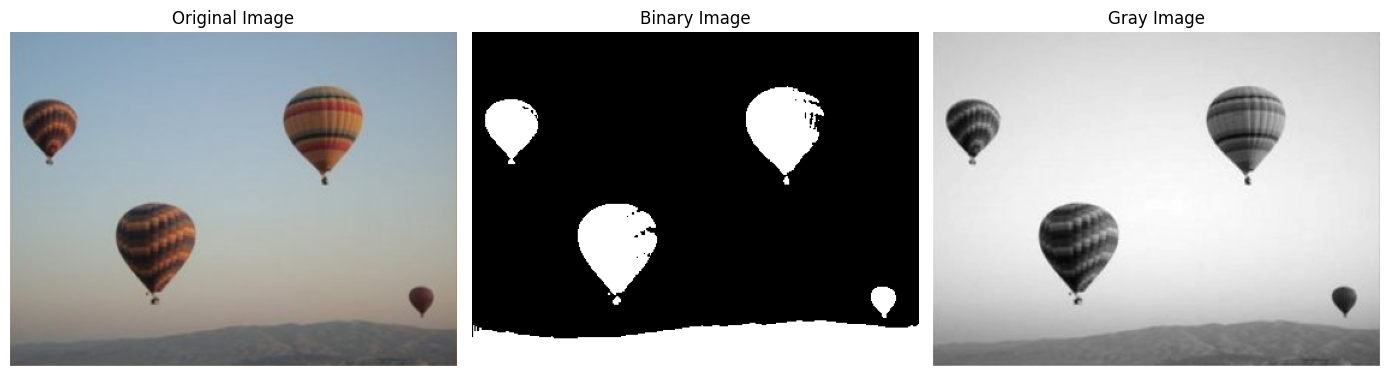

In [ ]:
input_image = cv2.imread(input_path)
if input_image is None:
  raise ValueError('The Input Image Could Not Be Loaded')

gray_image = cv2.cvtColor(input_image, cv2.COLOR_BGR2GRAY)

_, binary_image = cv2.threshold(gray_image, 127, 255, cv2.THRESH_BINARY_INV)

plt.figure(figsize=(14, 8))

plt.subplot(1, 3, 1)
plt.title('Original Image')
plt.imshow(cv2.cvtColor(input_image, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title('Binary Image')
plt.imshow(binary_image, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title('Gray Image')
plt.imshow(gray_image, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

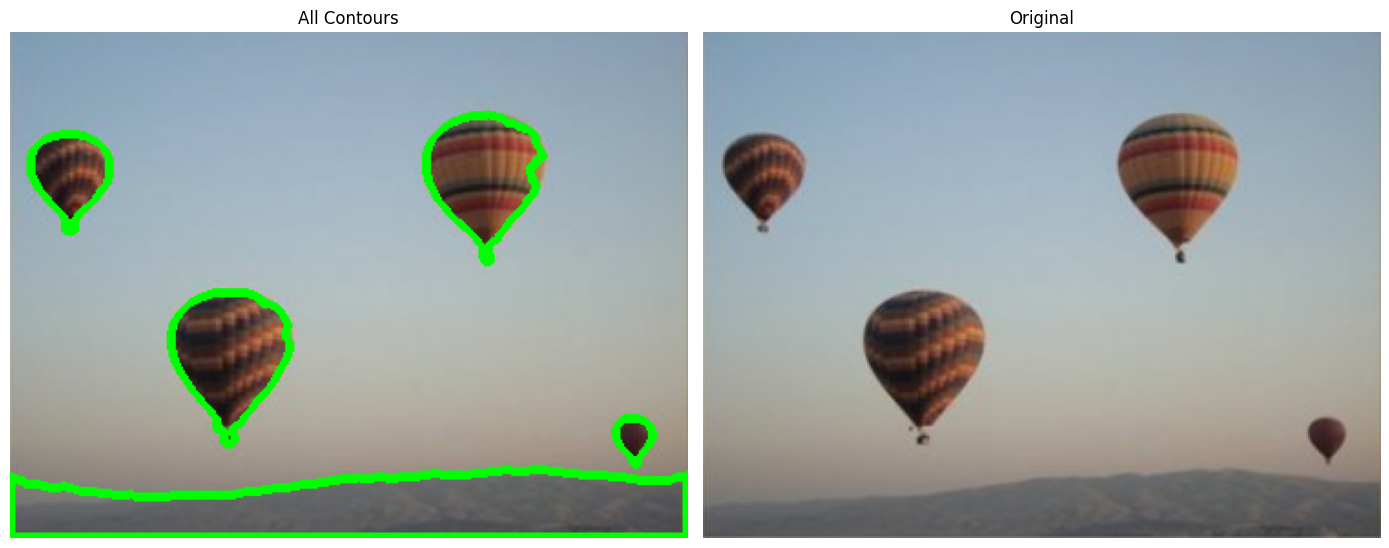

In [5]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5), (2, 2))

closed_image = cv2.morphologyEx(binary_image, cv2.MORPH_CLOSE, kernel)

contours, hierarchy = cv2.findContours(closed_image, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

if len(contours) < 3:
  raise ValueError('No Contours Found')

all_contours = cv2.drawContours(input_image.copy(), contours, -1, (0, 255, 0), 3)

plt.figure(figsize=(14, 8))

plt.subplot(1, 2, 1)
plt.title('All Contours')
plt.imshow(cv2.cvtColor(all_contours, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Original')
plt.imshow(cv2.cvtColor(input_image, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.tight_layout()
plt.show()

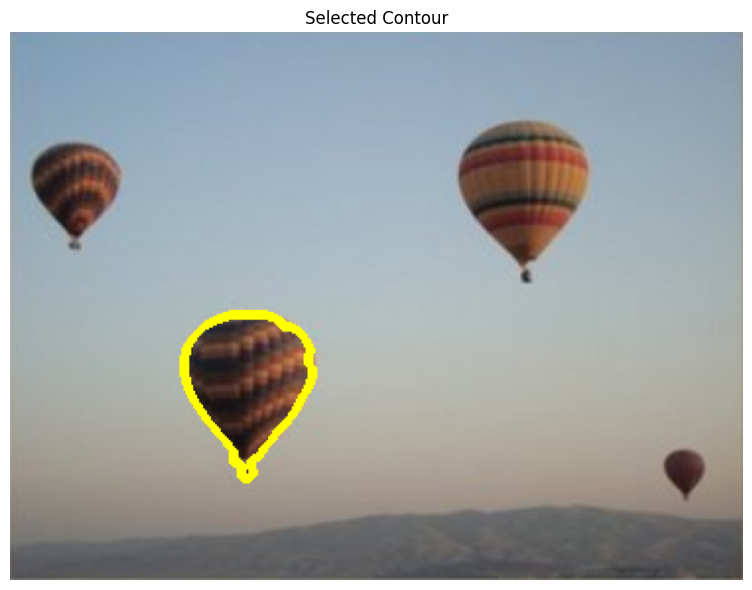

In [6]:
selected_contours_id = 2
selected_contour = contours[selected_contours_id]

selected_contour_image = cv2.drawContours(input_image.copy(), [selected_contour], -1, (0, 255, 255), 3)

plt.figure(figsize=(8, 6))

plt.title('Selected Contour')
plt.imshow(cv2.cvtColor(selected_contour_image, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
bounding_box = cv2.boundingRect(selected_contour)
center, radius = cv2.minEnclosingCircle(selected_contour)

x, y, w, h = bounding_box
center_x, center_y = center

print('Bounding Box:')
print('Minimum Enclosing Circle:')
print(f'center=({center_x:.2f}, {center_y:.2f}), radius={radius:.2f}')

Bounding Box:
Minimum Enclosing Circle:
center=(120.50, 183.99), radius=42.08


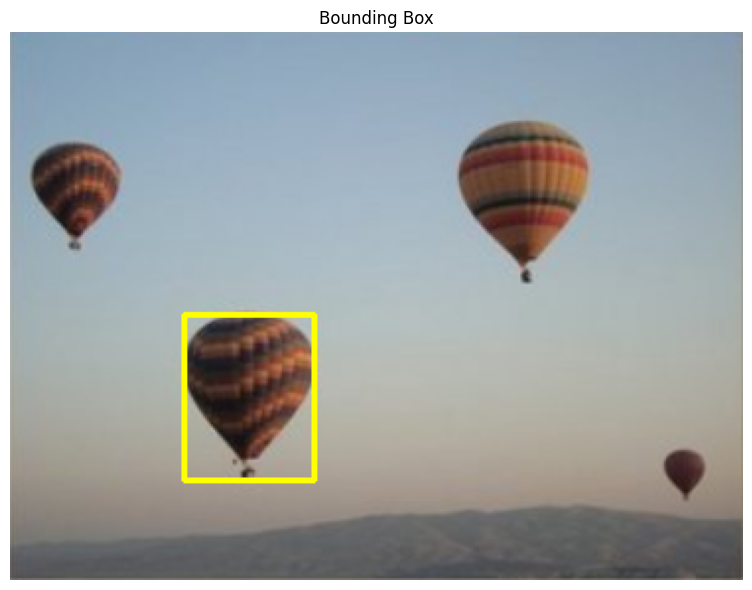

In [9]:
bounding_box_image = input_image.copy()

cv2.rectangle(bounding_box_image, (x, y), (x + w, y + h), (0, 255, 255), 2)

plt.figure(figsize=(8, 6))

plt.title('Bounding Box')
plt.imshow(cv2.cvtColor(bounding_box_image, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.tight_layout()
plt.show()

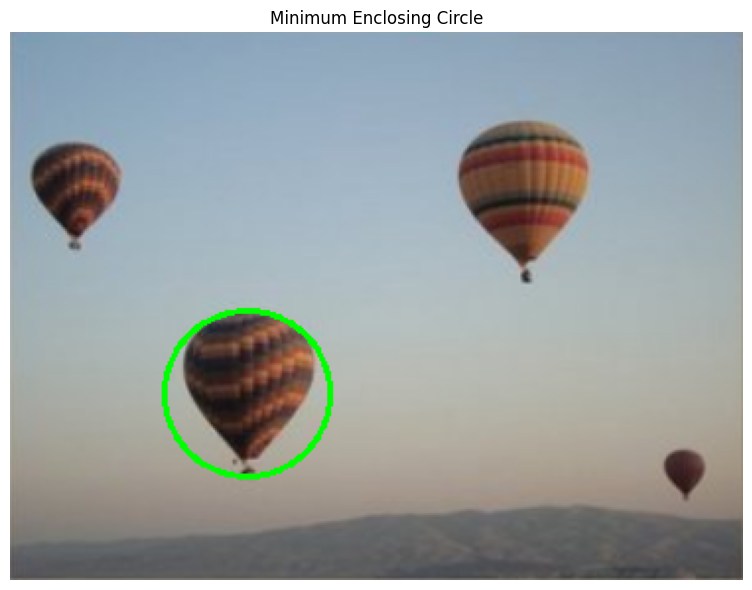

In [10]:
circle_image = input_image.copy()

cv2.circle(circle_image, (int(center_x), int(center_y)), int(radius), (0, 255, 0), 2)

plt.figure(figsize=(8, 6))

plt.title('Minimum Enclosing Circle')
plt.imshow(cv2.cvtColor(circle_image, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
output_images = {
    'all_contours': all_contours,
    'selected_contour': selected_contour_image,
    'bounding_box': bounding_box_image,
    'minimum_enclosing_circle': circle_image
}

for filename, output_image in output_images.items():
  output_path = '/content/' + filename + '.png'
  cv2.imwrite(output_path, output_image)
  files.download(output_path)
  print(f'Saved {filename}.png')
  print(f'Downloaded {filename}.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved all_contours.png
Downloaded all_contours.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Saved bounding_box.png
Downloaded bounding_box.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved minimum_enclosing_circle.png
Downloaded minimum_enclosing_circle.png
